In [3]:
import tensorflow as tf
from tensorflow import keras
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

In [4]:
#dataset
layers = tf.keras.layers
keras.utils.set_random_seed(42)
df = pd.read_csv("nasa.csv")
df.head()

,unit,cycle,setting1,setting2,setting3,sensor1,sensor2,sensor3,sensor4,sensor5,...,sensor14,sensor15,sensor16,sensor17,sensor18,sensor19,sensor20,sensor21,RUL,Fault_Label
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190,191,0
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236,190,0
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442,189,0
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739,188,0
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044,187,0


In [5]:
df = df.sort_values(["unit", "cycle"]).reset_index(drop=True)


In [6]:
sensors = [c for c in df.columns if c.startswith("sensor") and df[c].nunique() > 1]   # keep informative sensors only (RUL would leak the answer)
N_FEATURES = len(sensors)
data = df.copy()
data[sensors] = data.groupby("unit")[sensors].transform(lambda s: s.rolling(10, min_periods=1).mean())   # smooth each engine

In [7]:
#split
train_rows, test_rows = data[data.unit <= 80], data[data.unit > 80]       # split by engine, not by row
scaler = MinMaxScaler().fit(train_rows.loc[train_rows.Fault_Label == 0, sensors])

In [8]:
#window <- extra thing
def make_windows(rows):                                                   # windows inside each engine, label = last step
    X, y = [], []
    for u, g in rows.groupby("unit"):
        a, l = scaler.transform(g[sensors]), g["Fault_Label"].values
        for i in range(len(g) - 30 + 1):
            X.append(a[i:i + 30]); y.append(l[i + 30 - 1])
    return np.array(X, dtype="float32"), np.array(y)
Wtrall, ytr = make_windows(train_rows)
Xtes, yte = make_windows(test_rows)
Xtrn = Wtrall[ytr == 0]                                                   # healthy windows only

print(Xtrn.shape, Xtes.shape, yte.sum(),len(yte))

(11338, 30, 15) (3913, 30, 15) 620 3913


In [9]:
#layers
inp = keras.Input(shape=(30,N_FEATURES))
x = layers.LSTM(32)(inp)
x = layers.RepeatVector(30)(x)
x = layers.LSTM(32,return_sequences=True)(x)
out = layers.TimeDistributed(layers.Dense(N_FEATURES))(x)
ae = keras.Model(inp,out)
ae.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)             │ (None, 30, 15)              │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm (LSTM)                          │ (None, 32)                  │           6,144 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ repeat_vector (RepeatVector)         │ (None, 30, 32)              │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm_1 (LSTM)                        │ (None, 30, 32)              │           8,320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ time_distributed (TimeDistributed)   │ (None, 30, 15)              │             495 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 14,959 (58.43 KB)

 Trainable params: 14,959 (58.43 KB)

 Non-trainable params: 0 (0.00 B)

In [10]:
ae.compile(optimizer="adam",loss="mse",metrics=["mae"])
stop = keras.callbacks.EarlyStopping(monitor="val_loss",patience=4,restore_best_weights=True)
hist = ae.fit(Xtrn,Xtrn,epochs=20,batch_size=128,validation_split=0.1,callbacks=[stop])

Epoch 1/20
80/80 ━━━━━━━━━━━━━━━━━━━━ 4s 21ms/step - loss: 0.1217 - mae: 0.2676 - val_loss: 0.0131 - val_mae: 0.0845
Epoch 2/20
80/80 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - loss: 0.0090 - mae: 0.0670 - val_loss: 0.0055 - val_mae: 0.0536
Epoch 3/20
80/80 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - loss: 0.0044 - mae: 0.0475 - val_loss: 0.0034 - val_mae: 0.0429
Epoch 4/20
80/80 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - loss: 0.0028 - mae: 0.0391 - val_loss: 0.0026 - val_mae: 0.0378
Epoch 5/20
80/80 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - loss: 0.0023 - mae: 0.0357 - val_loss: 0.0023 - val_mae: 0.0356
Epoch 6/20
80/80 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - loss: 0.0021 - mae: 0.0343 - val_loss: 0.0021 - val_mae: 0.0345
Epoch 7/20
80/80 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - loss: 0.0020 - mae: 0.0335 - val_loss: 0.0020 - val_mae: 0.0338
Epoch 8/20
80/80 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - loss: 0.0019 - mae: 0.0329 - val_loss: 0.0020 - val_mae: 0.0331
Epoch 9/20
80/80 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - loss: 0.001

In [11]:
#reconstruction error
err_train = np.mean((Xtrn - ae.predict(Xtrn))**2,axis=(1,2))
err_test = np.mean((Xtes - ae.predict(Xtes))**2,axis=(1,2))
threshold = np.percentile(err_train,99)
pred = (err_test > threshold).astype(int)
print(threshold, pred.sum(),len(pred))

355/355 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
123/123 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
0.003100774453487245 321 3913


In [12]:
#evaluate
print(classification_report(yte,pred,target_names=["normal","anomaly"],digits=3))
print(confusion_matrix(yte,pred))
print(round(roc_auc_score(yte,err_test),4))

              precision    recall  f1-score   support

      normal      0.906     0.989     0.946      3293
     anomaly      0.885     0.458     0.604       620

    accuracy                          0.905      3913
   macro avg      0.896     0.723     0.775      3913
weighted avg      0.903     0.905     0.892      3913

[[3256   37]
 [ 336  284]]
0.9244


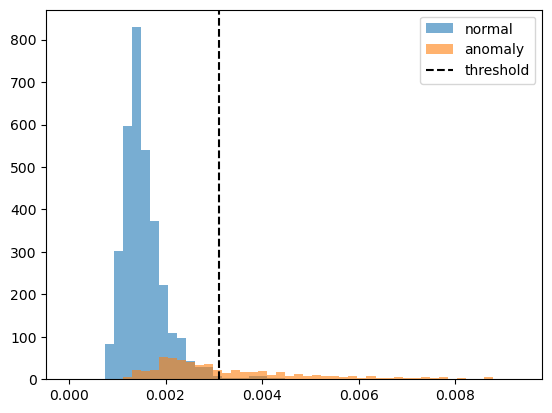

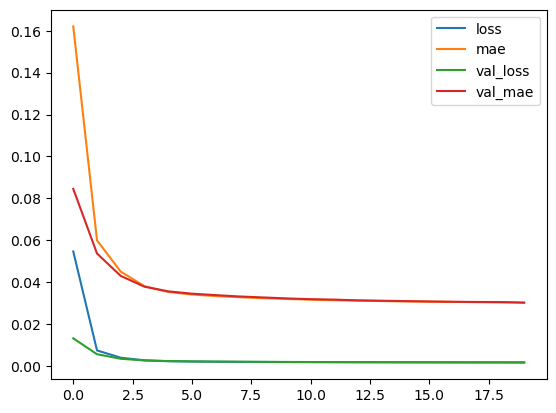

In [13]:
#plot
for k in (0,1):
    plt.hist(err_test[yte==k],50,range=(0,np.percentile(err_test,99)),alpha=0.6,label=["normal","anomaly"][k])
plt.axvline(threshold,color="k",ls="--",label="threshold")
plt.legend()
pd.DataFrame(hist.history).plot();
plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step


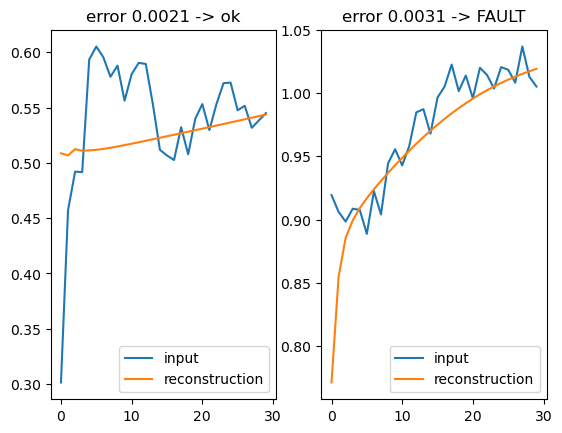

In [14]:
#one example
i = np.where(yte == 0)[0][0]                       # first healthy window
j = np.where((yte == 1) & (pred == 1))[0][0]       # first faulty window the model caught
for n, k in enumerate((i, j)):
    plt.subplot(1, 2, n+1); plt.plot(Xtes[k,:,0], label="input"); plt.plot(ae.predict(Xtes[k:k+1])[0,:,0], label="reconstruction")
    plt.title(f"error {err_test[k]:.4f} -> {'FAULT' if pred[k] else 'ok'}"); plt.legend()
plt.show()

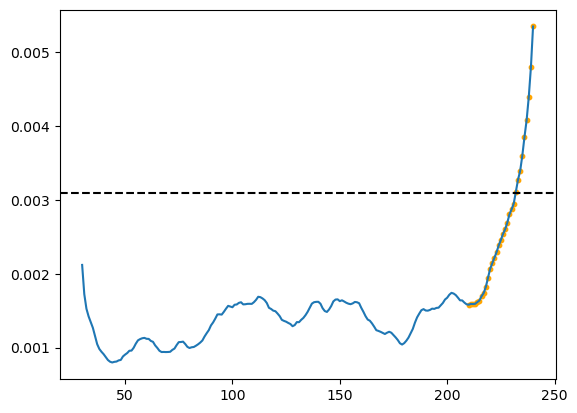

In [15]:
#error over time for one engine
g = test_rows[test_rows.unit == 81]; n = len(g) - 30 + 1                  # first test engine = first n windows
cyc, e81 = g["cycle"].values[29:], err_test[:n]
plt.plot(cyc, e81); plt.axhline(threshold, color="k", ls="--")            # error per cycle vs threshold
plt.scatter(cyc[yte[:n] == 1], e81[yte[:n] == 1], s=10, c="orange")       # true fault windows
plt.show()